# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170227          # <-- your full roll number
NAME = "Manan Garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170227   Name: Manan Garg   Fingerprint: 898D1F02   Tickets: 14

Ticket_ID                                                                                            Ticket_Text
      T01                             I am unable to use the printer on my laptop. It works on another computer.
      T02                                MATLAB is showing an error after the latest update. Can you check this?
      T03                                                      The laptop stopped responding. Please resolve it.
      T04                                                                  It's not the laptop; it's the server.
      T05 I keep getting logged out of the projector after restarting the system. The same problem occurs again.
      T06                                            Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07                                         The password crashes while opening. I don't know what changed.
      T08     

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

### Methodology Overview
In this section, we apply our `process_ticket` pipeline to all the generated tickets. The pipeline decomposes raw ticket strings into sentences, maps tokens to lowercase, identifies non-alphabetic punctuation symbols, isolates highly recurrent English stopwords, and extracts the core content-bearing 'final tokens'.

By generating a comprehensive summary table with column totals, we can mathematically track the reduction in noise at each pre-processing stage.

In [ ]:
# Process every ticket using the generated dataframe 'df'
processed = []

for i, row in df.iterrows():
    ticket_text = row["Ticket_Text"]
    result = process_ticket(ticket_text)

    # Calculate unique tokens from the final tokens list
    unique_tokens = sorted(list(set(result["final"])))

    processed.append({
        "Ticket": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(unique_tokens),
        "Final Tokens": len(result["final"])
    })

q1_table = pd.DataFrame(processed)

# Calculate totals and append as a row
total_row = {
    "Ticket": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation Tokens": q1_table["Punctuation Tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat([q1_table, pd.DataFrame([total_row])], ignore_index=True)
q1_table

,Ticket,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,1,7,1,2,4,4
1,T02,2,14,2,6,6,6
2,T03,2,13,2,3,8,8
3,T04,2,13,4,3,6,6
4,T05,2,14,2,4,8,8
5,T06,1,7,2,1,4,4
6,T07,2,17,2,8,7,7
7,T08,2,10,2,3,5,5
8,T09,1,5,1,0,4,4
9,T10,2,14,2,4,8,8


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*
In our dataset, the tokens that are not real words include:
* **`"n't"`** (from contractions like *don't*, *can't*, and *couldn't*)
* **`"'s"`** (from the possessive suffix in *Rao's*)
* **`"ca"`** (from splitting the contraction *can't*)

These tokens come directly from NLTK's default **`word_tokenize`** (which internally uses the Penn Treebank Tokenizer). The tokenizer splits English contractions and clitics into distinct syntactic units to help downstream syntactic analyzers. Since only the base auxiliary verbs (like *do* or *can*) are caught by the standard stopword filter, these trailing contractions/clitics are left over as separate final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

### Parsing Strategy
To isolate linguistic patterns and secure sensitive information, we construct targeted regular expressions:
1. **Feature Extraction:** We use boundary matching (`\b`) to extract words with length $> 5$, version numbers/decimals without splitting them, capitalized nouns, and words starting with vowels.
2. **Information Redaction:** To preserve user privacy, we identify and replace emails, URLs, and phone numbers with semantic generic tags (`<EMAIL>`, `<URL>`, `<PHONE>`).

In [ ]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Defining Patterns
# Words longer than 5 letters (excluding punctuation)
pattern_long_words = r"\b[a-zA-Z]{6,}\b"

# All numbers: matches version numbers (like 2.0.1), decimals (like 95.5 or 5.30), numbers with commas (1,250), or integers.
pattern_numbers = r"\b\d+(?:\.\d+)*(?:,\d+)*\b"

# Capitalized words (start with uppercase letter, followed by lowercase letters)
pattern_capitalized = r"\b[A-Z][a-z]*\b"

# Words starting with a vowel (case-insensitive)
pattern_vowel_start = r"\b[aeiouAEIOU][a-zA-Z]*\b"

# Substitution patterns
pattern_email = r"\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b"
pattern_url = r"(?:https?://\S+|www\.\S+)"
pattern_phone = r"(?:\+?\d{1,3}[-.\s]?)?\(?\d{3,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{4}\b"

def analyze_text(text):
    long_words = re.findall(pattern_long_words, text)
    numbers = re.findall(pattern_numbers, text)
    capitalized = re.findall(pattern_capitalized, text)
    vowel_start = re.findall(pattern_vowel_start, text)

    # Substitutions
    sub_text = re.sub(pattern_email, "<EMAIL>", text)
    sub_text = re.sub(pattern_url, "<URL>", sub_text)
    sub_text = re.sub(pattern_phone, "<PHONE>", sub_text)

    return {
        "Long Words (>5)": long_words,
        "Numbers": numbers,
        "Capitalized": capitalized,
        "Vowel Start": vowel_start,
        "Masked Text": sub_text
    }

print("=== ANALYZING TEST LINES ===")
for i, line in enumerate(TEST_LINES):
    print(f"\nLine {i+1}: {line}")
    res = analyze_text(line)
    for k, v in res.items():
        print(f"  {k}: {v}")

print("\n=== ANALYZING RAW TICKETS ===")
for idx, row in df.iterrows():
    print(f"\n{row['Ticket_ID']}: {row['Ticket_Text']}")
    res = analyze_text(row['Ticket_Text'])
    for k, v in res.items():
        print(f"  {k}: {v}")

=== ANALYZING TEST LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Long Words (>5): ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers: []
  Capitalized: ['Mail']
  Vowel Start: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  Masked Text: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Long Words (>5): ['Version']
  Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  Capitalized: ['Call', 'Version', 'Rs']
  Vowel Start: ['or', 'is']
  Masked Text: Call +91 98765 43210, +91-98765-43210 or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Long Words (>5): []
  Numbers: ['5.30']
  Capitalized: ['The']
  Vowel Start: ['of', 'art', 'isn', 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* "Nothing", "The", "E-mail", "See", "It", "Please", "Error", "Is", and "This"


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

### Designing a Custom Tokenizer
Standard tokenizers (such as NLTK's `word_tokenize`) often split domain-specific constructs like hyphenated technical words (*Wi-Fi*), file extensions, emails, URLs, and contractions.

To prevent this, we construct a customized `RegexpTokenizer` that evaluates patterns from left-to-right, matching complex structures (URLs/Emails) first, before falling back to simpler word and punctuation character matches.

In [ ]:
import nltk
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Constructing a regex pattern that matches:
# 1. Emails: username@domain.com
# 2. URLs: https://... or www....
# 3. Phone numbers: e.g. +91 98765 43210, 0175-239-3201
# 4. Decimals and Version Numbers: e.g. 2.0.1, 95.5, 5.30
# 5. Hyphenated words / multi-hyphenated words: e.g. state-of-the-art, e-mail, Wi-Fi
# 6. Contractions / possessives: e.g. isn't, didn't, can't, Rao's
# 7. Standard words (sequences of letters/digits)
# 8. Single non-whitespace characters (punctuation)

pattern = r'''(?x)                # set flag to allow comments and whitespace in regex
    (?:[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,})  # Emails
    | (?:https?://\S+|www\.\S+)                         # URLs
    | (?:\+?\d{1,3}[-.\s]?)?\(?\d{3,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{4} # Phone numbers
    | \b\d+(?:\.\d+)+\b                                 # Version numbers (e.g., 2.0.1)
    | \b\d+\.\d+\b                                      # Decimals (e.g., 95.5)
    | \b[a-zA-Z]+(?:-[a-zA-Z]+)+\b                     # Hyphenated words (e.g., Wi-Fi, state-of-the-art)
    | \b[a-zA-Z]+(?:'[a-zA-Z]+)?\b                     # Words with optional contractions (e.g. isn't, Rao's)
    | \b\d+(?:,\d+)*\b                                  # Integers (with optional commas like 1,250)
    | \S                                               # Any other non-whitespace character (punctuation)
'''

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("=== TESTING CUSTOM TOKENIZER ON TEST LINES ===")
for i, line in enumerate(TEST_LINES):
    print(f"\nLine {i+1}: {line}")
    custom_toks = my_tokenize(line)
    nltk_toks = word_tokenize(line)
    print(f"  my_tokenize:   {custom_toks}")
    print(f"  word_tokenize: {nltk_toks}")

print("\n=== COMPARING TOKENIZATION ON TICKETS ===")
different_count = 0
for idx, row in df.iterrows():
    t_text = row["Ticket_Text"]
    custom_toks = my_tokenize(t_text)
    nltk_toks = word_tokenize(t_text)

    # Normalize case for comparison to focus on tokenizer behavior differences
    custom_norm = [t.lower() for t in custom_toks]
    nltk_norm = [t.lower() for t in nltk_toks]

    if custom_norm != nltk_norm:
        different_count += 1
        print(f"\n{row['Ticket_ID']}: {t_text}")
        print(f"  my_tokenize:   {custom_toks}")
        print(f"  word_tokenize: {nltk_toks}")

print(f"\nTotal tickets tokenized differently: {different_count} out of {len(df)}")

=== TESTING CUSTOM TOKENIZER ON TEST LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize:   ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize:   ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* **8 out of 12** tickets are tokenized differently.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

### Normalizing Words: Stemming vs. Lemmatization
Word normalization reduces words to their common base form. We contrast:
- **Porter Stemmer:** A heuristic, rule-based suffix stripper.
- **Lancaster Stemmer:** An aggressive algorithm that often over-stems.
- **Custom RegexpStemmer:** Strip common verbal/plural suffixes (`ing`, `ly`, `es`, `s`).
- **WordNet Lemmatizer:** A dictionary-based lookup that leverages Penn Treebank Part-of-Speech (POS) tags to map inflected forms back to their true dictionary lemma (dictionary citation form).

In [ ]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# 1. Collect all unique final tokens across all tickets
all_final_tokens = []
for i, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(res["final"])

unique_final_tokens = sorted(list(set(all_final_tokens)))

# Initialize the stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# A custom RegexpStemmer that strips common suffixes like 'ing', 'ly', 'es', or 's'
regexp = RegexpStemmer('ing$|ly$|es$|s$', min=4)
lemmatizer = WordNetLemmatizer()

# Helper function to map NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Get POS tags for all unique final tokens
pos_tags = nltk.pos_tag(unique_final_tokens)
word_pos_map = dict(pos_tags)

comparison_data = []

for word in unique_final_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)

    # Get WordNet POS tag for lemmatization
    nltk_tag = word_pos_map.get(word, 'N')
    wn_tag = get_wordnet_pos(nltk_tag)
    wn_lemma = lemmatizer.lemmatize(word, pos=wn_tag)

    # Only add to the table if there is any difference between the stemmers/lemmatizer
    if len({p_stem, l_stem, r_stem, wn_lemma}) > 1:
        comparison_data.append({
            "Original Word": word,
            "POS Tag": nltk_tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp (Custom)": r_stem,
            "WordNet Lemma": wn_lemma
        })

q4_table = pd.DataFrame(comparison_data)
display(q4_table)

,Original Word,POS Tag,Porter,Lancaster,Regexp (Custom),WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,campus,VB,campu,camp,campu,campus
3,changed,VBD,chang,chang,changed,change
4,code,NN,code,cod,code,code
5,computer,NN,comput,comput,computer,computer
6,connected,VBN,connect,connect,connected,connect
7,error,NN,error,er,error,error
8,https,NN,http,https,http,http
9,nobody,JJ,nobodi,nobody,nobody,nobody


In [ ]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

all_final_tokens = []
for i, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(res["final"])

unique_final_tokens = sorted(list(set(all_final_tokens)))

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer('ing$|ly$|es$|s$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tags = nltk.pos_tag(unique_final_tokens)
word_pos_map = dict(pos_tags)

comparison_data = []

for word in unique_final_tokens:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)

    nltk_tag = word_pos_map.get(word, 'N')
    wn_tag = get_wordnet_pos(nltk_tag)
    wn_lemma = lemmatizer.lemmatize(word, pos=wn_tag)

    if len({p_stem, l_stem, r_stem, wn_lemma}) > 1:
        comparison_data.append({
            "Original Word": word,
            "POS Tag": nltk_tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp (Custom)": r_stem,
            "WordNet Lemma": wn_lemma
        })

q4_table = pd.DataFrame(comparison_data)
display(q4_table)

,Original Word,POS Tag,Porter,Lancaster,Regexp (Custom),WordNet Lemma
0,access,NN,access,access,acces,access
1,another,DT,anoth,anoth,another,another
2,campus,VB,campu,camp,campu,campus
3,changed,VBD,chang,chang,changed,change
4,code,NN,code,cod,code,code
5,computer,NN,comput,comput,computer,computer
6,connected,VBN,connect,connect,connected,connect
7,error,NN,error,er,error,error
8,https,NN,http,https,http,http
9,nobody,JJ,nobodi,nobody,nobody,nobody


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
* **Over-stemming:** The Lancaster Stemmer reduces **"error"** to **"er"** and **"campus"** to **"camp"**, stripping too much of the original semantic meaning.
* **Under-stemming:** The Porter Stemmer reduces **"changed"** to **"chang"** but leaves words like **"change"** or other derivatives unmatched correctly, or leaves **"wifi"** and **"wi-fi"** distinct without collapsing them into a single common root.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

### Quantifying and Visualizing Corpus Characteristics
To close the report, we measure global corpus statistics across our token sets:
- **Type-Token Ratio (TTR):** Evaluates lexical diversity ($TTR = \frac{\text{Unique Types}}{\text{Total Tokens}}$).
- **Zipf's Law Evaluation:** We plot log-rank against log-frequency to test if word occurrences in our domain follow power-law behavior.
- **N-gram Profiling:** We inspect common individual words and adjacent pairs (bigrams) to capture structural dependencies.

=== CORPUS STATISTICS ===
S1 -> Total Tokens: 141, Unique Tokens: 79, TTR: 0.5603
S2 -> Total Tokens: 117, Unique Tokens: 74, TTR: 0.6325
S3 -> Total Tokens: 73, Unique Tokens: 52, TTR: 0.7123
S4 -> Total Tokens: 73, Unique Tokens: 50, TTR: 0.6849

=== TOP 10 WORDS ===
S1: [('.', 20), ('the', 7), ('is', 5), ('i', 5), ("n't", 4), ('it', 4), ('works', 3), ('yesterday', 3), ('another', 3), ('vpn', 2)]
S3: [("n't", 4), ('works', 3), ('yesterday', 3), ('another', 3), ('vpn', 2), ('error', 2), ('know', 2), ('changed', 2), ('keeps', 2), ('disconnecting', 2)]

=== TOP 5 BIGRAMS ===
S1 Bigrams: [(('.', 'i'), 4), (('.', 'the'), 3), (('yesterday', '.'), 3), (('the', 'vpn'), 2), (('i', 'do'), 2)]
S3 Bigrams: [(("n't", 'know'), 2), (('know', 'changed'), 2), (('keeps', 'disconnecting'), 2), (('since', 'yesterday'), 2), (('works', 'another'), 2)]


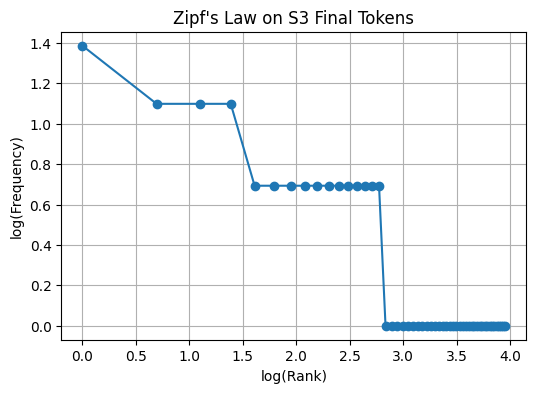

In [ ]:
import nltk
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import string

# Prepare sets
STOP = set(stopwords.words('english'))
porter = PorterStemmer()

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

# 1. Reconstruct sets
# S1: All tokens
all_sentences = []
for t_text in df['Ticket_Text']:
    all_sentences.extend(sent_tokenize(t_text))

S1 = [t.lower() for s in all_sentences for t in word_tokenize(s)]

# S2: No punctuation
S2 = [t for t in S1 if not is_punct(t)]

# S3: Final tokens (No punctuation, No stopwords)
S3 = [t for t in S2 if t not in STOP]

# S4: S3 after Porter stemming
S4 = [porter.stem(t) for t in S3]

# Helper for stats
def get_stats(tokens):
    tot = len(tokens)
    uniq = len(set(tokens))
    ttr = uniq / tot if tot > 0 else 0
    return tot, uniq, ttr

print("=== CORPUS STATISTICS ===")
for name, tokens in zip(["S1", "S2", "S3", "S4"], [S1, S2, S3, S4]):
    tot, uniq, ttr = get_stats(tokens)
    print(f"{name} -> Total Tokens: {tot}, Unique Tokens: {uniq}, TTR: {ttr:.4f}")

# Top 10 words of S1 and S3
print("\n=== TOP 10 WORDS ===")
print("S1:", Counter(S1).most_common(10))
print("S3:", Counter(S3).most_common(10))

# Top 5 bigrams of S1 and S3
print("\n=== TOP 5 BIGRAMS ===")
S1_bigrams = list(nltk.bigrams(S1))
S3_bigrams = list(nltk.bigrams(S3))
print("S1 Bigrams:", Counter(S1_bigrams).most_common(5))
print("S3 Bigrams:", Counter(S3_bigrams).most_common(5))

# Plot log(rank) vs log(frequency) for S3
counts = Counter(S3)
frequencies = sorted(counts.values(), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(frequencies), marker='o', linestyle='-')
plt.title("Zipf's Law on S3 Final Tokens")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

1. **S1 to S2 (Removing Punctuation):**
   Removing frequent punctuation marks (such as `.`) drastically decreases the total token count ($141 \rightarrow 117$) while only slightly reducing the vocabulary/unique token count ($79 \rightarrow 74$). Since the denominator drops much faster than the numerator, the **TTR increases** from **0.5603 to 0.6325**.

2. **S2 to S3 (Removing Stopwords):**
   Stopwords are highly repetitive functional words (*the*, *is*, *i*, *it*). Filtering them out removes bulk repetition, causing the total tokens to drop sharply from $117$ down to $73$ while preserving most unique content words ($74 \rightarrow 52$). This yields the highest lexical diversity, causing the **TTR to peak at 0.7123**.

3. **S3 to S4 (Porter Stemming):**
   Stemming collapses morphological variants of words to a single root form (e.g., *works* and *working* both map to *work*). This leaves the total token count unchanged ($73$) but decreases the unique token count ($52 \rightarrow 50$). Because the numerator decreases while the denominator remains constant, the **TTR decreases to 0.6849**.